# Analysis of population stratification

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns

from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil

## Load Humans

In [2]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [3]:
dim = pd.read_pickle('./data/phenotype/reduction_of_ae_2_dims_5001_seconds.pkl')
dim = pd.read_pickle('./data/phenotype/reduction_of_ae_2_dims_153_seconds.pkl')

In [4]:
humans = pd.concat([humans,dim.reindex(humans.index)], axis = 1)
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2
0,HG00096,HG00096,GBR,EUR,male,-1.425541,-2.568410
1,HG00097,HG00097,GBR,EUR,female,-1.440646,-2.603086
2,HG00099,HG00099,GBR,EUR,female,-0.860363,-3.086992
3,HG00100,HG00100,GBR,EUR,female,-0.975774,-2.796563
4,HG00101,HG00101,GBR,EUR,male,-0.637032,-3.063057
...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.273707,-0.582326
2500,NA21141,NA21141,GIH,SAS,female,0.299007,-0.676079
2501,NA21142,NA21142,GIH,SAS,female,0.294150,-0.659157
2502,NA21143,NA21143,GIH,SAS,female,0.516370,-0.759748


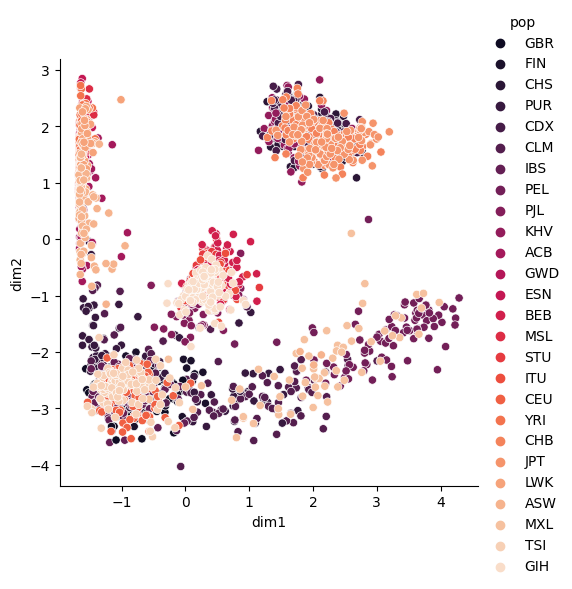

In [5]:
g = sns.relplot(
    data=humans,
    x="dim1", y="dim2",
    hue="pop",
    palette='rocket', sizes=(10, 200))
plt.show()

In [6]:
score = sil.silhouette_score(humans[[f"dim1",f"dim2"]], humans['super_pop'], metric='euclidean')
score

0.6293693

# Load snps

In [7]:
os.listdir('./data/genotype')

['chrom_21', 'chrom_22']

In [8]:
min_maf = 0
max_maf = 0.3

In [9]:
snps = [f for f in os.listdir('./data/genotype') if  max_maf > float(f.split("_maf_")[1].split('.pkl')[0].split('_')[0]) > min_maf]
snps

IndexError: list index out of range

In [ ]:
snp_num = 0
for snp in snps[0:1]:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    print(maf)
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)
    geno = pd.read_pickle(path_snp)
    
    geno[geno.columns[snp_num]].value_counts()
    num_maj = geno[geno.columns[snp_num]].value_counts()[1]
    num_het = geno[geno.columns[snp_num]].value_counts()[0]
    try:
        num_min = geno[geno.columns[snp_num]].value_counts()[-1]
    except Exception as e:
        num_min = 0
    total_humans = num_maj + num_het + num_min
    maf = (num_min*2 + num_het)/(total_humans*2)
    humans[str(round(maf,3))] = geno[geno.columns[snp_num]]

In [ ]:
humans

In [ ]:
maf

In [ ]:
g = sns.relplot(
    data=humans,
    x="dim1", y="dim2",
    hue=f"{str(round(maf,3))}",
    palette='rocket', sizes=(10, 200))
plt.show()

## Scenario 1: AF + popstrat dependent phenotype (LD snps)

In [ ]:
max_maf = 0.05
min_maf = 0

In [ ]:
dims = [f for f in os.listdir('./data/phenotype/reduced/21') if  max_maf > float(f.split("_maf_")[1].split('.pkl')[0].split('_')[0]) > min_maf]
dims

In [ ]:
snp_num = 0
for dim in dims[1:2]:
    maf = dim.split("_maf_")[1].split('.pkl')[0].split("_")[0]
    print(maf)
    path_snp = f"./data/phenotype/reduced/21/{dim}"
    print(path_snp)
    mini_dim = pd.read_pickle(path_snp)


In [ ]:
humans[f"maf_{maf}_dim1"] = mini_dim['dim1']
humans[f"maf_{maf}_dim2"] = mini_dim['dim2']

In [10]:
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2
0,HG00096,HG00096,GBR,EUR,male,-1.425541,-2.568410
1,HG00097,HG00097,GBR,EUR,female,-1.440646,-2.603086
2,HG00099,HG00099,GBR,EUR,female,-0.860363,-3.086992
3,HG00100,HG00100,GBR,EUR,female,-0.975774,-2.796563
4,HG00101,HG00101,GBR,EUR,male,-0.637032,-3.063057
...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.273707,-0.582326
2500,NA21141,NA21141,GIH,SAS,female,0.299007,-0.676079
2501,NA21142,NA21142,GIH,SAS,female,0.294150,-0.659157
2502,NA21143,NA21143,GIH,SAS,female,0.516370,-0.759748


In [11]:
g = sns.relplot(
    data=humans,
    x=f"maf_{maf}_dim1", y=f"maf_{maf}_dim2",
    hue="super_pop",
    palette='rocket', sizes=(10, 200))
plt.show()

NameError: name 'maf' is not defined

In [12]:
print(np.random.seed(10))

None


In [13]:
# create 3 samples of random dots
dif = 100
ratio = 0.1
mean = 0
mean1 = mean - dif
mean2 = mean
mean3 = mean + dif
sigma = dif * ratio
s11 = np.random.normal(mean1, sigma, 1000)
s12 = np.random.normal(mean1, sigma, 1000)
label1 = ['label 1'] * len(s11)

s21 = np.random.normal(mean2, sigma, 1000)
s22 = np.random.normal(mean2, sigma, 1000)
label2 = ['label 2'] * len(s21)

s31 = np.random.normal(mean3, sigma, 1000)
s32 = np.random.normal(mean3, sigma, 1000)
label3 = ['label 3'] * len(s31)

In [14]:
df = pd.DataFrame({"dim1":np.concatenate((s11, s21, s31)), "dim2": np.concatenate((s12, s22, s32)), 'label': label1 + label2 + label3})

In [15]:
df

,dim1,dim2,label
0,-86.684135,-84.867478,label 1
1,-92.847210,-101.423336,label 1
2,-115.454003,-101.394200,label 1
3,-100.083838,-88.244925,label 1
4,-93.786640,-88.162110,label 1
...,...,...,...
2995,111.535213,87.553371,label 3
2996,92.809537,98.706436,label 3
2997,85.574458,90.125523,label 3
2998,103.883900,106.401594,label 3


In [16]:
km = KMeans(n_clusters=3, random_state=42)
km.fit_predict(df[['dim1','dim2']])

array([0, 0, 0, ..., 1, 1, 1], dtype=int32)

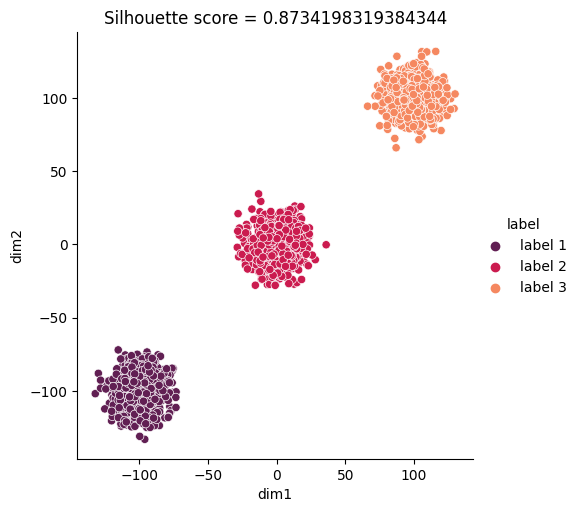

In [17]:
g = sns.relplot(
    data=df,
    x=f"dim1", y=f"dim2",
    hue="label",
    palette='rocket', sizes=(10, 200)).set(
    title=f"Silhouette score = {sil.silhouette_score(df[['dim1','dim2']], df['label'], metric='euclidean')}")
plt.show()

In [44]:
km = KMeans(n_clusters=3, random_state=42)
km.fit_predict(df[['dim1','dim2']])

array([0, 0, 0, ..., 1, 1, 1], dtype=int32)

In [25]:
score = sil.silhouette_score(df[['dim1','dim2']], km.labels_, metric='euclidean')
score

0.5035900985976353

In [26]:
score = sil.silhouette_score(df[['dim1','dim2']], df['label'], metric='euclidean')

In [27]:
score

0.47304216661557835

In [28]:
df['pred_label'] = km.labels_

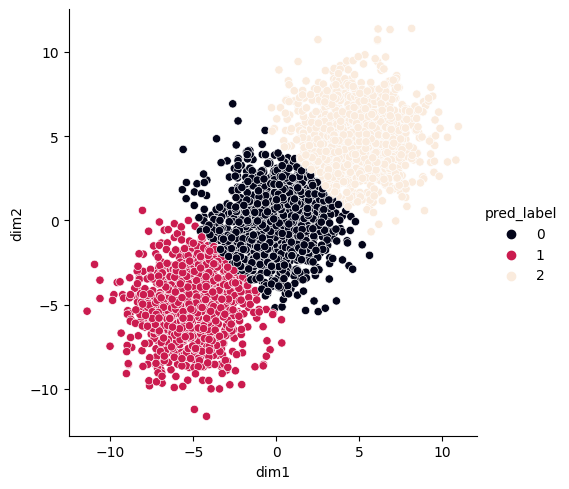

In [29]:
g = sns.relplot(
    data=df,
    x=f"dim1", y=f"dim2",
    hue="pred_label",
    palette='rocket', sizes=(10, 200))
plt.show()

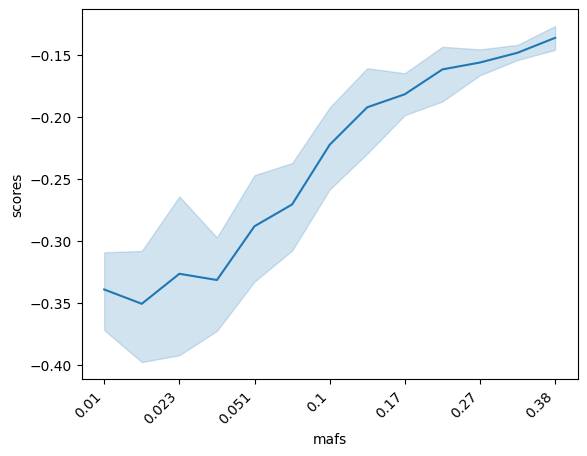

In [56]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/21')]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/21/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

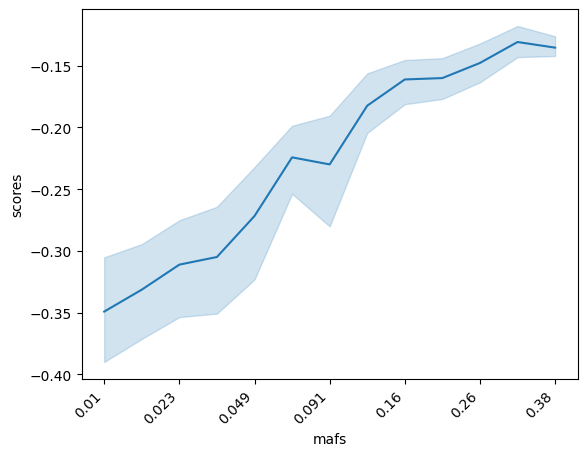

In [57]:
sil_scores = []
mafs = []
dims = [f for f in os.listdir('./data/phenotype/reduced/22')]
dimsy = dims[0:-1]
for o in range(len(dimsy)):
    maf = dimsy[o].split("_maf_")[1].split('.pkl')[0].split("_")[0]
    path_dim = f"./data/phenotype/reduced/22/{dimsy[o]}"
    mini_dim = pd.read_pickle(path_dim)
    humans[f"{o}_maf_{maf}_dim1"] = mini_dim['dim1']
    humans[f"{o}_maf_{maf}_dim2"] = mini_dim['dim2']
    score = sil.silhouette_score(humans[[f"{o}_maf_{maf}_dim1",f"{o}_maf_{maf}_dim2"]], humans['pop'], metric='euclidean')
    sil_scores.append(score)
    mafs.append(maf)

df = pd.DataFrame(data = {'scores':sil_scores, 'mafs':mafs})
df = df.sort_values(by=['mafs'], ignore_index=True)
sns.lineplot(data=df, x="mafs", y="scores")
plt.xticks(
    df['mafs'].iloc[::20], # Odd rows only
    rotation=45,
    horizontalalignment='right'
)
plt.show()

In [37]:
humans

,sample,sample.1,pop,super_pop,gender,dim1,dim2,0.037,maf_0.37_dim1,maf_0.37_dim2,...,123_maf_0.049_dim1,123_maf_0.049_dim2,124_maf_0.26_dim1,124_maf_0.26_dim2,125_maf_0.035_dim1,125_maf_0.035_dim2,127_maf_0.26_dim1,127_maf_0.26_dim2,128_maf_0.21_dim1,128_maf_0.21_dim2
0,HG00096,HG00096,GBR,EUR,male,-1.425541,-2.568410,1,-0.043317,1.015291,...,0.008046,0.083890,-0.304385,1.545435,0.609630,0.459884,-0.809544,0.658253,-0.411755,-1.921741
1,HG00097,HG00097,GBR,EUR,female,-1.440646,-2.603086,1,-0.193059,0.241459,...,-1.762927,0.776143,-0.118009,-0.744123,0.634930,0.459177,-0.132031,-0.339630,-0.428542,-1.822935
2,HG00099,HG00099,GBR,EUR,female,-0.860363,-3.086992,1,-0.465019,-0.228906,...,-1.843851,1.275335,-0.083373,-0.716782,0.642941,0.467813,-0.480714,0.656090,1.830391,-1.989670
3,HG00100,HG00100,GBR,EUR,female,-0.975774,-2.796563,1,-1.331270,0.576430,...,-1.294101,-0.912099,-0.226724,0.371060,0.569442,0.380161,0.653000,-1.419537,-0.490716,-1.652104
4,HG00101,HG00101,GBR,EUR,male,-0.637032,-3.063057,1,-0.442783,-0.101128,...,-0.466540,-0.287250,-0.391644,-0.859911,0.662238,0.497847,-1.095393,-0.078781,0.877813,-1.302985
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,0.273707,-0.582326,1,0.528698,0.908940,...,-1.632482,1.867299,0.079528,-0.893112,0.563259,0.384423,2.088614,0.196759,-0.765023,1.459558
2500,NA21141,NA21141,GIH,SAS,female,0.299007,-0.676079,1,0.026765,-0.334037,...,-0.864438,1.923548,0.438989,-0.791244,0.497364,0.268296,2.113688,0.265050,-1.224695,1.185272
2501,NA21142,NA21142,GIH,SAS,female,0.294150,-0.659157,1,0.344574,1.124886,...,-0.084149,1.381633,0.118426,-0.944797,0.465278,0.530333,-0.194871,1.026547,0.859509,-0.021716
2502,NA21143,NA21143,GIH,SAS,female,0.516370,-0.759748,1,0.649083,-0.539392,...,0.101086,1.097910,-0.114350,-0.895959,0.462088,0.456379,1.042228,0.382429,1.079839,-0.645303
